# Capstone EDA: predicting serious delinquency in consumer credit

Group 4 | October 2026 | eHA Academy Data Science Capstone, FinTech Risk and Fraud track

**Question:** which borrowers become 90 or more days past due within 2 years?

**Data:** Kaggle Give Me Some Credit, file cs-training.csv, 150,000 borrowers.

**Sprint 1 goal:** collect, clean and explore the data.

### How this report maps to the modules

| Module | Method used here |
|---|---|
| 1-2 | Environment setup, data source, loading the competition files |
| 3 | Data profiling, cleaning log, new columns |
| 4 | Distributions, each input against delinquency, correlations |
| 5 | Confidence interval, hypothesis tests, Bayes' theorem |
| 6-7 | Train and test split, baseline and stronger model, precision, recall and PR-AUC |
| 8 | Power BI dashboard and live demo |

# Module 1-2: Setup and data acquisition

## Get the data

The files were downloaded from the Kaggle competition page and saved in the Dataset folder of the project. This notebook reads cs-training.csv.

In [72]:
# Import os to list files and join paths
import os

# Import pandas to read the csv
import pandas as pd

# Folder that holds the downloaded competition files
data_dir = "Dataset"

# List the files to confirm cs-training.csv is there
print(os.listdir(data_dir))

['cs-test.csv', 'cs-training.csv', 'Data Dictionary.xls', 'sampleEntry.csv']


# Module 1-2: Setup and data acquisition

## Get the data

The files were downloaded from the Kaggle competition page and saved in the Dataset folder of the project. This notebook reads cs-training.csv.

In [73]:
# Read the training file from the Dataset folder
df = pd.read_csv(os.path.join(data_dir, "cs-training.csv"))

# Show the number of rows and columns
print(df.shape)

# Show the column names and their types
print(df.dtypes)

# Show the first five rows
df.head()

(150000, 12)
Unnamed: 0                                int64
SeriousDlqin2yrs                          int64
RevolvingUtilizationOfUnsecuredLines    float64
age                                       int64
NumberOfTime30-59DaysPastDueNotWorse      int64
DebtRatio                               float64
MonthlyIncome                           float64
NumberOfOpenCreditLinesAndLoans           int64
NumberOfTimes90DaysLate                   int64
NumberRealEstateLoansOrLines              int64
NumberOfTime60-89DaysPastDueNotWorse      int64
NumberOfDependents                      float64
dtype: object


,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


# Module 3: Data wrangling

## Structure and missing values

Check the column types, how many values are missing in each column, and whether any rows are duplicated.

In [74]:
# Show the column types and the count of non-missing values
df.info()

# Count the missing values in each column
missing_count = df.isna().sum()

# Turn the counts into percentages of all rows
missing_pct = (missing_count / len(df) * 100).round(2)

# Put counts and percentages in one table, largest first
missing_table = pd.DataFrame({"missing": missing_count, "percent": missing_pct})
print(missing_table.sort_values("missing", ascending=False))

# Count duplicate rows, ignoring the first column because it is a row number
print("Duplicate rows:", df.iloc[:, 1:].duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 12 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Unnamed: 0                            150000 non-null  int64  
 1   SeriousDlqin2yrs                      150000 non-null  int64  
 2   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 3   age                                   150000 non-null  int64  
 4   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 5   DebtRatio                             150000 non-null  float64
 6   MonthlyIncome                         120269 non-null  float64
 7   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 8   NumberOfTimes90DaysLate               150000 non-null  int64  
 9   NumberRealEstateLoansOrLines          150000 non-null  int64  
 10  NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 11  NumberOfDep

## Target balance

Check how many borrowers became seriously delinquent.

In [75]:
# Count the borrowers in each class of the target
counts = df["SeriousDlqin2yrs"].value_counts()

# Work out each class as a percentage of all borrowers
shares = (df["SeriousDlqin2yrs"].value_counts(normalize=True) * 100).round(2)

# Print counts and percentages together
print(pd.DataFrame({"count": counts, "percent": shares}))

                   count  percent
SeriousDlqin2yrs                 
0                 139974    93.32
1                  10026     6.68


### What this shows

The training file has 150,000 rows and 12 columns: a row number, the target and 10 inputs. MonthlyIncome is missing for 29,731 borrowers (19.82%) and NumberOfDependents for 3,924 (2.62%). No other column has missing values. 609 rows are exact duplicates once the row number is ignored.

Of the 150,000 borrowers, 10,026 (6.68%) became seriously delinquent and 139,974 (93.32%) did not. A model that predicts "no delinquency" for everyone would be right 93.32% of the time and find no one, so accuracy cannot be our score.

## Summary statistics

Check the range of each column and look for values that cannot be right.

In [76]:
# Show summary statistics for every column, with extra percentiles to spot extreme values
print(df.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T.round(2))

# Count borrowers younger than 18, who should not appear in a credit file
print("Age below 18:", (df["age"] < 18).sum())

                                         count      mean       std  min  \
Unnamed: 0                            150000.0  75000.50  43301.41  1.0   
SeriousDlqin2yrs                      150000.0      0.07      0.25  0.0   
RevolvingUtilizationOfUnsecuredLines  150000.0      6.05    249.76  0.0   
age                                   150000.0     52.30     14.77  0.0   
NumberOfTime30-59DaysPastDueNotWorse  150000.0      0.42      4.19  0.0   
DebtRatio                             150000.0    353.01   2037.82  0.0   
MonthlyIncome                         120269.0   6670.22  14384.67  0.0   
NumberOfOpenCreditLinesAndLoans       150000.0      8.45      5.15  0.0   
NumberOfTimes90DaysLate               150000.0      0.27      4.17  0.0   
NumberRealEstateLoansOrLines          150000.0      1.02      1.13  0.0   
NumberOfTime60-89DaysPastDueNotWorse  150000.0      0.24      4.16  0.0   
NumberOfDependents                    146076.0      0.76      1.12  0.0   

                        

In [77]:
# Show only the 99th percentile and the maximum for each column
print(df.describe(percentiles=[0.99]).T[["99%", "max"]].round(2))

# Past-due columns to check for placeholder codes
due_cols = ["NumberOfTime30-59DaysPastDueNotWorse", "NumberOfTimes90DaysLate", "NumberOfTime60-89DaysPastDueNotWorse"]

# Count the rows holding the values 96 or 98 in each past-due column
for col in due_cols:
    print(col, "| 96:", (df[col] == 96).sum(), "| 98:", (df[col] == 98).sum())

# Count borrowers whose utilisation is above 1, meaning balances above their limits
print("Utilisation above 1:", (df["RevolvingUtilizationOfUnsecuredLines"] > 1).sum())

# Count borrowers with a monthly income of 0
print("Income of 0:", (df["MonthlyIncome"] == 0).sum())

                                            99%        max
Unnamed: 0                            148500.01   150000.0
SeriousDlqin2yrs                           1.00        1.0
RevolvingUtilizationOfUnsecuredLines       1.09    50708.0
age                                       87.00      109.0
NumberOfTime30-59DaysPastDueNotWorse       4.00       98.0
DebtRatio                               4979.04   329664.0
MonthlyIncome                          25000.00  3008750.0
NumberOfOpenCreditLinesAndLoans           24.00       58.0
NumberOfTimes90DaysLate                    3.00       98.0
NumberRealEstateLoansOrLines               4.00       54.0
NumberOfTime60-89DaysPastDueNotWorse       2.00       98.0
NumberOfDependents                         4.00       20.0
NumberOfTime30-59DaysPastDueNotWorse | 96: 5 | 98: 264
NumberOfTimes90DaysLate | 96: 5 | 98: 264
NumberOfTime60-89DaysPastDueNotWorse | 96: 5 | 98: 264
Utilisation above 1: 3321
Income of 0: 1634


### What the summary statistics show

Age has a minimum of 0 and one borrower is under 18. The three past-due columns hold the values 98 (264 rows) and 96 (5 rows) with identical counts, which points to placeholder codes and not real counts. RevolvingUtilizationOfUnsecuredLines reaches 50,708 although its 99th percentile is 1.09, and 3,321 borrowers are above 1. DebtRatio reaches 329,664 against a 99th percentile of 4,979. 1,634 borrowers report a monthly income of 0, and the maximum income is 3,008,750 against a 99th percentile of 25,000.

## Cleaning, stage A

In [78]:
# Import numpy for the missing value marker
import numpy as np

# Work on a copy so the original df stays available for comparison
clean = df.copy()

# Rename the unnamed first column to row_id
clean = clean.rename(columns={"Unnamed: 0": "row_id"})

# Names of the three past-due columns
due_cols = ["NumberOfTime30-59DaysPastDueNotWorse", "NumberOfTimes90DaysLate", "NumberOfTime60-89DaysPastDueNotWorse"]

# Rows holding a 96 or 98 code in all three columns, and in any of them
code_all = clean[due_cols].isin([96, 98]).all(axis=1)
code_any = clean[due_cols].isin([96, 98]).any(axis=1)
print("Code in all three columns:", code_all.sum(), "| in any column:", code_any.sum())

# Delinquency rate in the code rows compared with all rows
print("Delinquency rate in code rows:", round(clean.loc[code_any, "SeriousDlqin2yrs"].mean() * 100, 2), "%")
print("Delinquency rate in all rows:", round(clean["SeriousDlqin2yrs"].mean() * 100, 2), "%")

# Step 1: remove exact duplicates, ignoring row_id
before = len(clean)
clean = clean.drop_duplicates(subset=[c for c in clean.columns if c != "row_id"])
print("Duplicates removed:", before - len(clean))

# Step 2: remove borrowers younger than 18
before = len(clean)
clean = clean[clean["age"] >= 18]
print("Removed for age below 18:", before - len(clean))

# Step 3: replace the placeholder codes 96 and 98 with missing values
for col in due_cols:
    clean[col] = clean[col].replace([96, 98], np.nan)

# Show the rows left and the missing counts that remain
print("Rows left:", len(clean))
print(clean.isna().sum()[clean.isna().sum() > 0])

Code in all three columns: 269 | in any column: 269
Delinquency rate in code rows: 54.65 %
Delinquency rate in all rows: 6.68 %
Duplicates removed: 609
Removed for age below 18: 1
Rows left: 149390
NumberOfTime30-59DaysPastDueNotWorse      225
MonthlyIncome                           29221
NumberOfTimes90DaysLate                   225
NumberOfTime60-89DaysPastDueNotWorse      225
NumberOfDependents                       3828
dtype: int64


### Cleaning stage A: result and decision

609 duplicate rows were removed, one borrower with an age below 18 was removed, and 149,390 rows remain. The codes 96 and 98 appear in the same 269 rows across the three past-due columns. 54.65% of those borrowers became delinquent, against 6.68% overall, so the codes carry information and replacing them without a trace would discard it. Decision: add a flag column that marks these borrowers, treat the codes as missing in the three past-due columns, and fill them after the split. The flag may reflect how the competition data was built and not real borrower behaviour, so the model will be tested with and without it, and the result will be stated as a limit.

In [79]:
# Rows with a code are the rows that now have missing values in the past-due columns
clean["past_due_code_flag"] = clean[due_cols[0]].isna().astype(int)

# Count the flagged borrowers and compute their delinquency rate after duplicates were removed
flagged = clean["past_due_code_flag"].sum()
rate = clean.loc[clean["past_due_code_flag"] == 1, "SeriousDlqin2yrs"].mean() * 100
print("Flagged borrowers:", flagged)
print("Delinquency rate of flagged borrowers:", round(rate, 2), "%")

# Confirm the flag matches the missing values in all three past-due columns
print("Flag matches all three columns:", (clean[due_cols].isna().all(axis=1) == (clean["past_due_code_flag"] == 1)).all())

Flagged borrowers: 225
Delinquency rate of flagged borrowers: 60.44 %
Flag matches all three columns: True


## New columns (feature engineering)

Six new columns group the borrowers so they can be compared in charts and tests: delinquent (Yes or No), age_group, income_band, utilisation_band, total_late and late_group. The income cut points are the quartiles from the summary statistics. Borrowers with missing income and the flagged code rows each get their own group so they are not hidden.

In [80]:
# Work on a copy so the stage A result stays unchanged
fe = clean.copy()

# Readable label for the target
fe["delinquent"] = fe["SeriousDlqin2yrs"].map({0: "No", 1: "Yes"})

# Age group
fe["age_group"] = pd.cut(fe["age"], bins=[17, 29, 44, 59, 120], labels=["18-29", "30-44", "45-59", "60+"])

# Income band using the quartiles from the summary statistics, with missing income as its own group
fe["income_band"] = pd.cut(fe["MonthlyIncome"], bins=[-1, 0, 3400, 5400, 8249, np.inf], labels=["0", "1-3,400", "3,401-5,400", "5,401-8,249", "Above 8,249"])
fe["income_band"] = fe["income_band"].cat.add_categories("Missing").fillna("Missing")

# Utilisation band, where above 1 means balances over the limit
fe["utilisation_band"] = pd.cut(fe["RevolvingUtilizationOfUnsecuredLines"], bins=[-0.001, 0.15, 0.56, 1, np.inf], labels=["Up to 0.15", "0.15-0.56", "0.56-1", "Above 1"])

# Total late payments across the three past-due columns, left empty for the flagged code rows
fe["total_late"] = fe[due_cols].sum(axis=1, min_count=3)

# Late payment group, with the flagged code rows as their own group
fe["late_group"] = pd.cut(fe["total_late"], bins=[-1, 0, 2, np.inf], labels=["None", "1-2", "3 or more"])
fe["late_group"] = fe["late_group"].cat.add_categories("Code rows").fillna("Code rows")

# Check each grouping: borrowers per group and the delinquency rate in the group
for col in ["age_group", "income_band", "utilisation_band", "late_group"]:
    table = fe.groupby(col, observed=True)["SeriousDlqin2yrs"].agg(borrowers="count", rate="mean")
    table["rate"] = (table["rate"] * 100).round(2)
    print(table)
    print()

           borrowers   rate
age_group                  
18-29           8609  11.92
30-44          38920   9.50
45-59          53788   7.04
60+            48073   3.12

             borrowers  rate
income_band                 
0                 1616  4.02
1-3,400          28575  9.53
3,401-5,400      30025  7.87
5,401-8,249      29894  6.07
Above 8,249      30059  4.62
Missing          29221  5.66

                  borrowers   rate
utilisation_band                  
Up to 0.15            74013   1.92
0.15-0.56             38229   4.98
0.56-1                33827  16.10
Above 1                3321  37.25

            borrowers   rate
late_group                  
None           119083   2.74
1-2             23173  15.26
3 or more        6909  44.55
Code rows         225  60.44



In [81]:
# Show the late_group table again, because the earlier output was cut off
table = fe.groupby("late_group", observed=True)["SeriousDlqin2yrs"].agg(borrowers="count", rate="mean")

# Turn the rate into a percentage
table["rate"] = (table["rate"] * 100).round(2)

# Print the table
print(table)

            borrowers   rate
late_group                  
None           119083   2.74
1-2             23173  15.26
3 or more        6909  44.55
Code rows         225  60.44


### What this shows

Delinquency falls as age rises: 11.92% for borrowers aged 18 to 29 and 3.12% for those aged 60 and over, almost four times lower. It also falls as income rises, from 9.53% in the 1 to 3,400 band to 4.62% above 8,249. The groups with an income of 0 (4.02%, 1,616 borrowers) and with missing income (5.66%) do not follow that pattern, so they should not be treated as high risk without further checking.

Utilisation shows the widest spread. The rate is 1.92% up to 0.15, 16.10% between 0.56 and 1, and 37.25% above 1, about 19 times the lowest group. Late payments point the same way: 15.26% for 1 to 2 late payments, 44.55% for 3 or more, and 60.44% for the 225 flagged code rows. The overall rate is about 6.7%.

These are rates by group. They show association, not cause, and the tests in Module 5 will check whether the differences are larger than chance.

# Module 4: Exploratory data analysis

## Delinquency rate by group

The same four groupings as charts, with the overall rate as a dashed line for comparison.

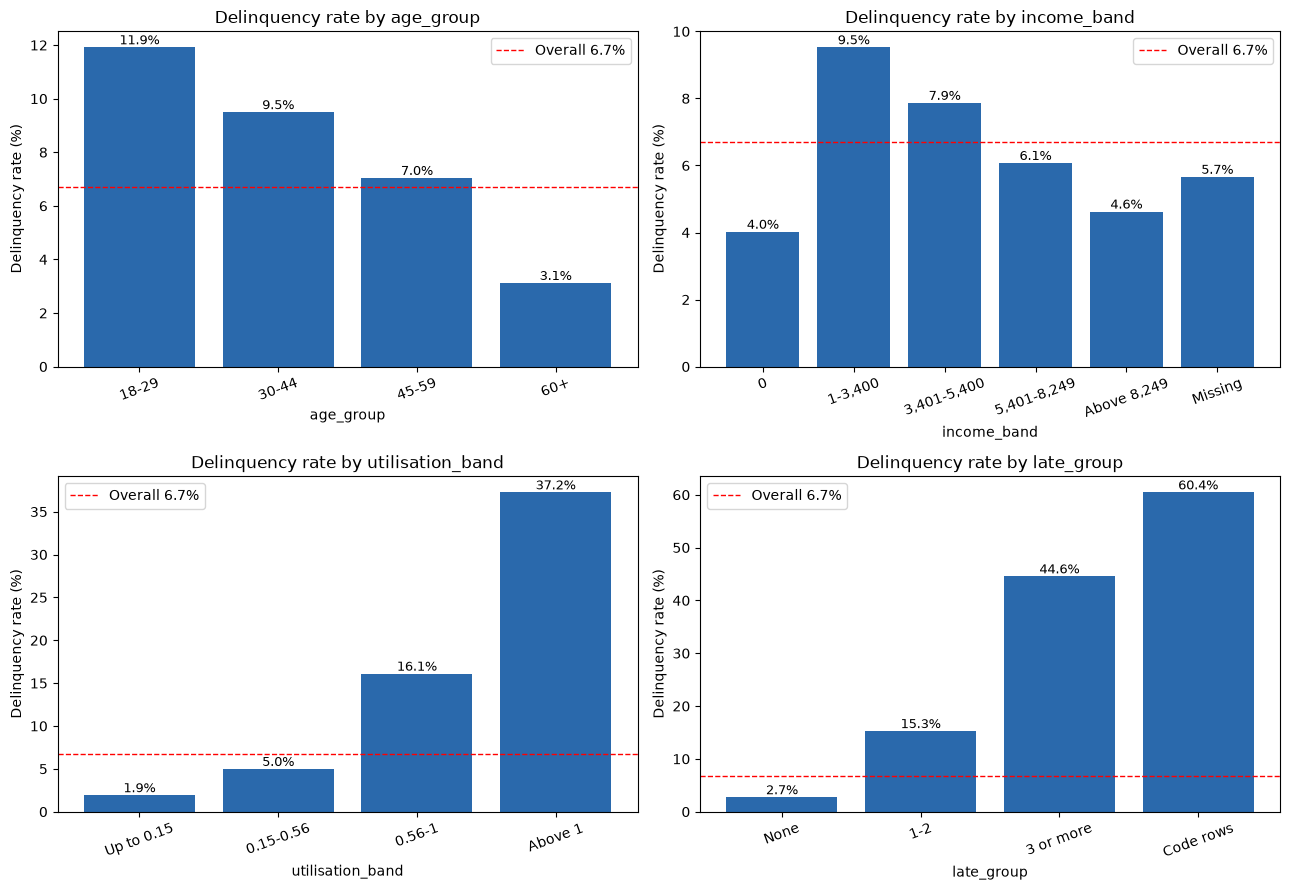

In [82]:
# Import matplotlib for charts
import matplotlib.pyplot as plt

# Group columns to plot, in the order of the tables above
group_cols = ["age_group", "income_band", "utilisation_band", "late_group"]

# Overall delinquency rate of the cleaned data, drawn as a reference line
overall = fe["SeriousDlqin2yrs"].mean() * 100

# One chart per grouping, two rows of two
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Loop over the four groupings and the four chart areas together
for ax, col in zip(axes.flat, group_cols):
    # Delinquency rate in each group, in percent
    rates = fe.groupby(col, observed=True)["SeriousDlqin2yrs"].mean() * 100
    # Draw the bars
    bars = ax.bar(rates.index.astype(str), rates.values, color="#2a69ac")
    # Label each bar with its rate
    ax.bar_label(bars, fmt="%.1f%%", fontsize=9)
    # Draw the overall rate as a dashed line
    ax.axhline(overall, color="red", linestyle="--", linewidth=1, label=f"Overall {overall:.1f}%")
    # Titles and axis labels
    ax.set_title(f"Delinquency rate by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Delinquency rate (%)")
    ax.legend()
    ax.tick_params(axis="x", rotation=20)

# Fit the layout and show the figure
plt.tight_layout()
plt.show()

Late payments point the same way: 2.7% for the 119,083 borrowers with none, 15.26% for 1 to 2 late payments, 44.55% for 3 or more, and 60.44% for the 225 flagged code rows.

### What the charts show

Late payments and utilisation separate borrowers most clearly. The rate rises from 2.7% for borrowers with no late payments to 15.3% for 1 to 2, 44.6% for 3 or more, and 60.4% for the flagged code rows. Utilisation rises from 1.9% to 37.2%. Age falls from 11.9% in the youngest group to 3.1% in the oldest. The income chart is not a straight line: borrowers with an income of 0 (4.0%) or missing income (5.7%) sit below the 1 to 3,400 band (9.5%). The dashed line is the overall rate of 6.7%.

## Distributions of the numeric inputs

For each numeric input: mean, median, spread, skewness, kurtosis, the 99th percentile and the maximum, followed by histograms. The histograms stop at the 99th percentile so extreme values do not squash the chart. This affects the charts only, and the data is unchanged.

                                         mean   median       std  skewness  \
RevolvingUtilizationOfUnsecuredLines     6.07     0.15    250.26     97.43   
age                                     52.31    52.00     14.73      0.19   
DebtRatio                              354.44     0.37   2041.85     94.98   
MonthlyIncome                         6675.10  5400.00  14389.64    114.02   
NumberOfOpenCreditLinesAndLoans          8.48     8.00      5.14      1.22   
NumberRealEstateLoansOrLines             1.02     1.00      1.13      3.48   
NumberOfDependents                       0.76     0.00      1.12      1.58   
total_late                               0.40     0.00      1.10      4.59   

                                      kurtosis       p99        max  
RevolvingUtilizationOfUnsecuredLines  14485.58      1.09    50708.0  
age                                      -0.49     87.00      109.0  
DebtRatio                             13681.50   4985.11   329664.0  
MonthlyIncome    

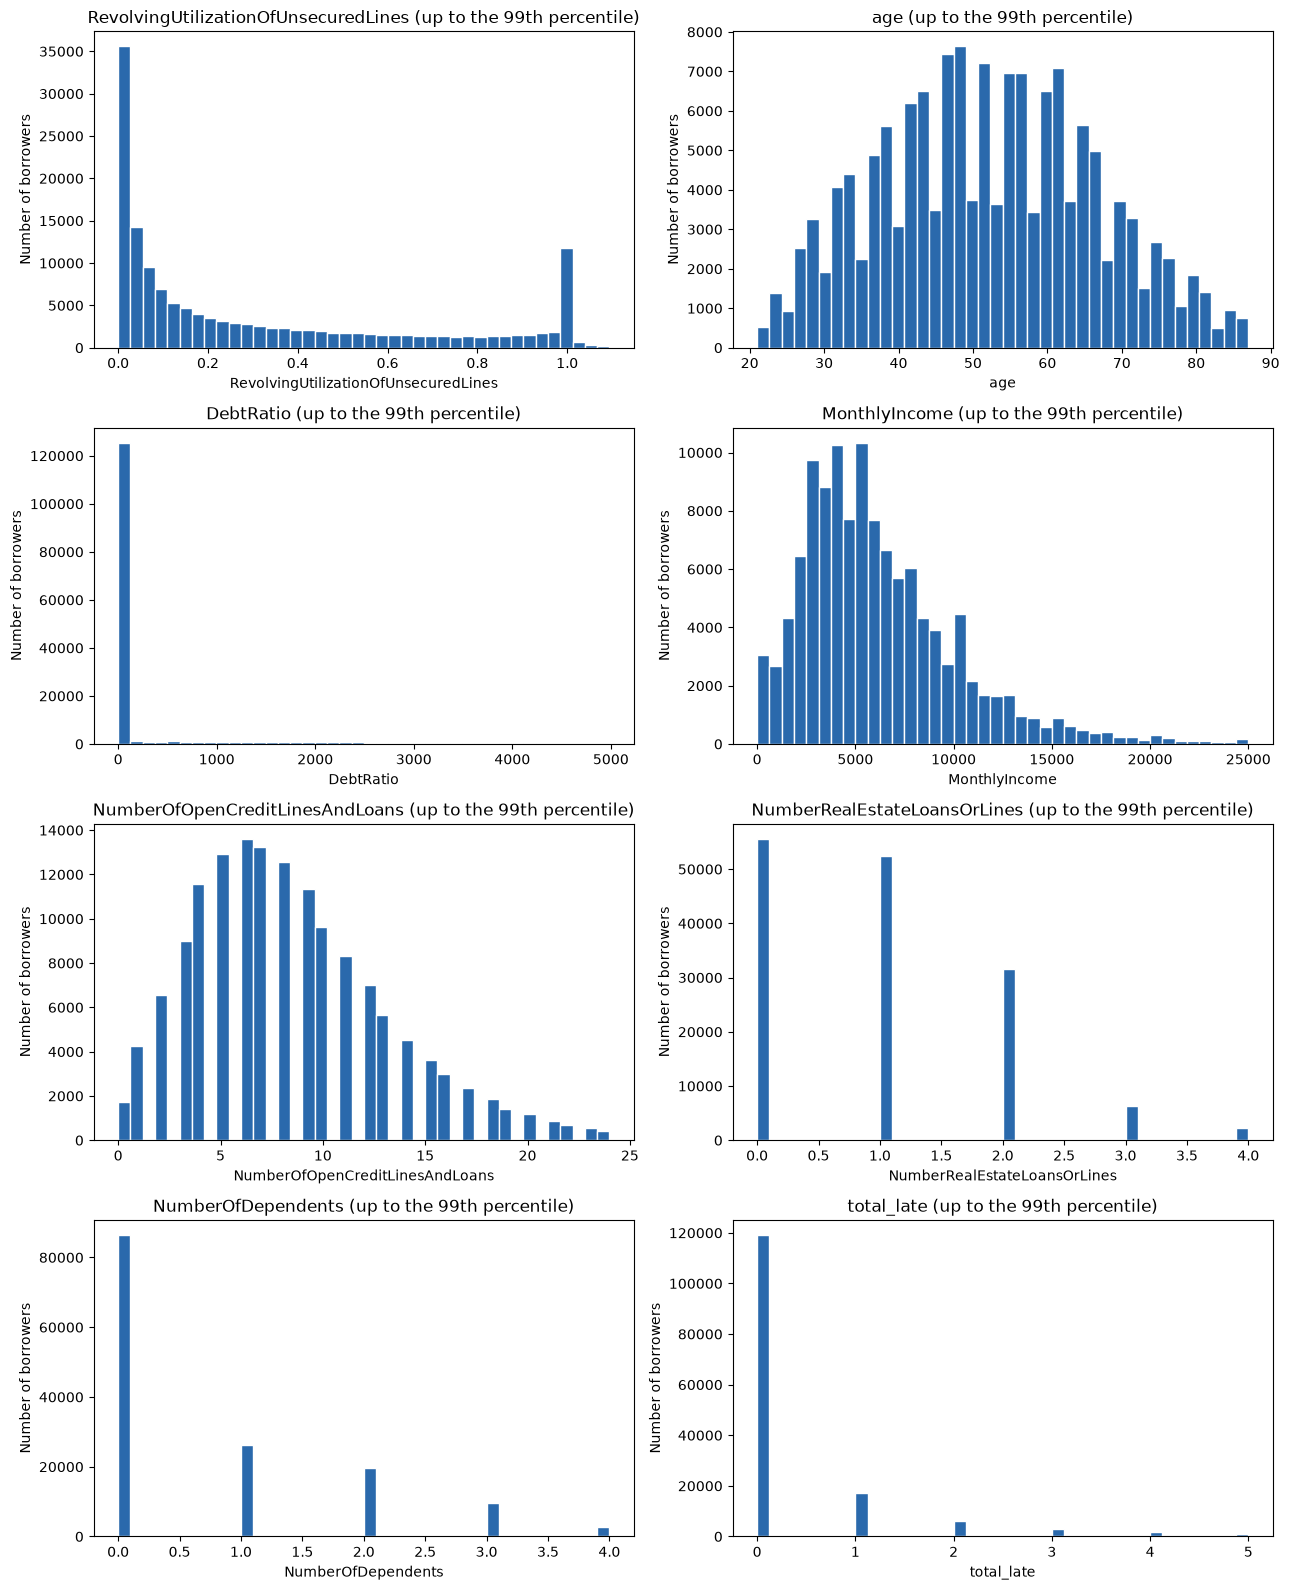

In [83]:
# Numeric inputs to explore, including the total late payments column
num_cols = ["RevolvingUtilizationOfUnsecuredLines", "age", "DebtRatio", "MonthlyIncome",
            "NumberOfOpenCreditLinesAndLoans", "NumberRealEstateLoansOrLines",
            "NumberOfDependents", "total_late"]

# Summary table for each column, using all rows that have a value
stats_table = pd.DataFrame({
    "mean": fe[num_cols].mean(),
    "median": fe[num_cols].median(),
    "std": fe[num_cols].std(),
    "skewness": fe[num_cols].skew(),
    "kurtosis": fe[num_cols].kurt(),
    "p99": fe[num_cols].quantile(0.99),
    "max": fe[num_cols].max()
}).round(2)
print(stats_table)

# Four rows of two histograms
fig, axes = plt.subplots(4, 2, figsize=(13, 16))

# Draw one histogram per column
for ax, col in zip(axes.flat, num_cols):
    # Values that are not missing
    data = fe[col].dropna()
    # The 99th percentile, used only to limit what the chart shows
    cap = data.quantile(0.99)
    # Histogram of the values up to that cap
    ax.hist(data[data <= cap], bins=40, color="#2a69ac", edgecolor="white")
    # Title and axis labels
    ax.set_title(f"{col} (up to the 99th percentile)")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of borrowers")

# Fit the layout and show the figure
plt.tight_layout()
plt.show()

### What the distributions show

Age is close to symmetric, with a mean of 52.31 and a median of 52. The other inputs are not. Utilisation, debt ratio and monthly income have means far above their medians (6.07 against 0.15, 354.44 against 0.37, and 6,675 against 5,400) and a skewness above 90, because a few extreme values pull the mean up. For these columns we report the median, since the mean describes almost no real borrower.

Utilisation has two spikes: about 35,000 borrowers sit near 0 and more than 11,000 sit at 1.0, which is the credit limit. Debt ratio is so concentrated that almost every borrower falls in the first bar, even after the chart is cut at the 99th percentile of 4,985. A debt ratio above 4,985 is not credible as a ratio, and it needs a decision in cleaning stage B. Monthly income peaks near 4,000 to 5,500 with a long right tail, and open credit lines peak at 6 to 7. Real estate loans, dependents and total late payments are small whole numbers. 119,083 borrowers have no late payment at all, and the median for dependents and total late payments is 0.

The statistics use every borrower with a value. The histograms are cut at the 99th percentile for display only, and the data is unchanged.

## Numeric inputs against delinquency

Compare borrowers who became delinquent with those who did not. The medians are used because the means are pulled up by extreme values. The boxplots are cut at the 99th percentile for display only.

delinquent                                 No      Yes
RevolvingUtilizationOfUnsecuredLines     0.13     0.84
age                                     52.00    45.00
DebtRatio                                0.36     0.43
MonthlyIncome                         5475.00  4500.00
NumberOfOpenCreditLinesAndLoans          8.00     7.00
total_late                               0.00     1.00


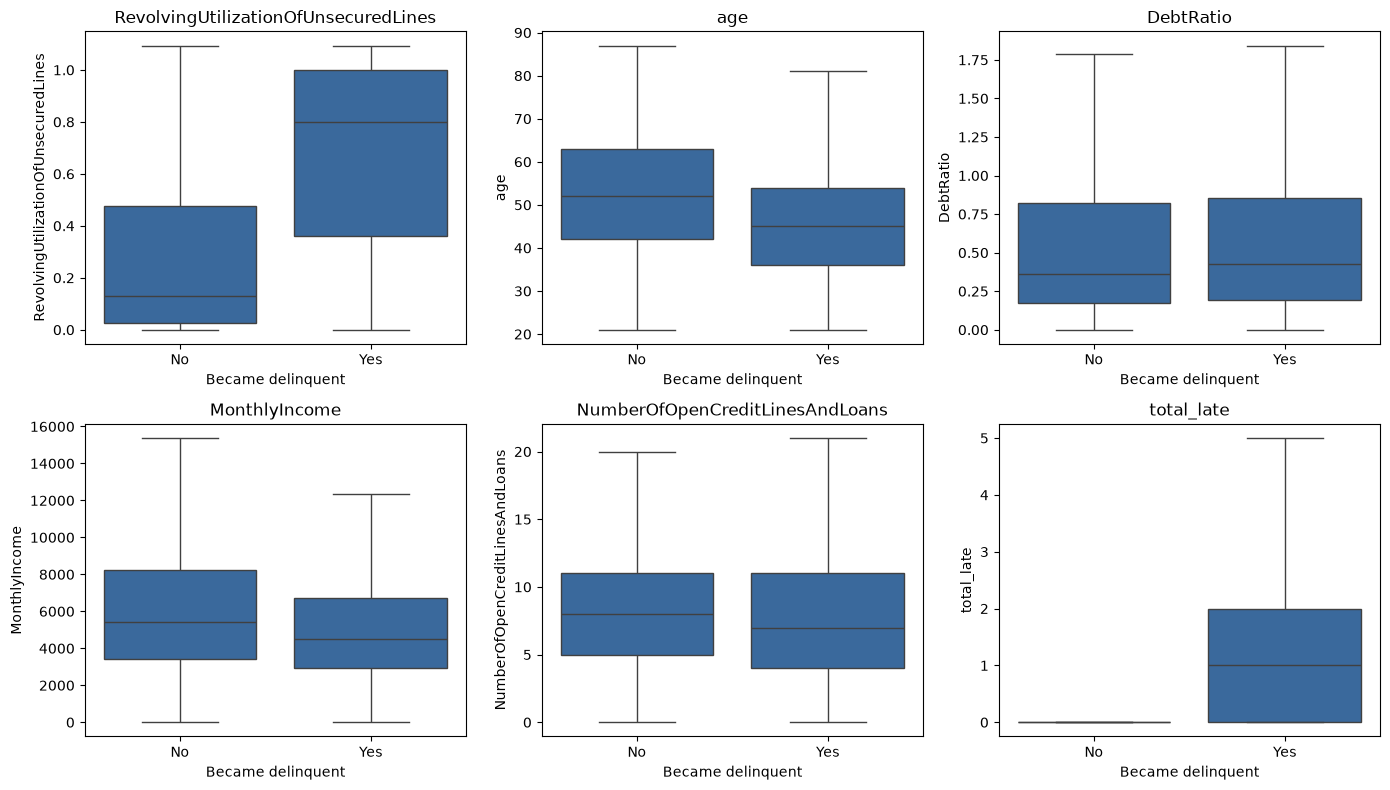

In [84]:
# Import seaborn for boxplots
import seaborn as sns

# Columns to compare between the two groups
cmp_cols = ["RevolvingUtilizationOfUnsecuredLines", "age", "DebtRatio", "MonthlyIncome",
            "NumberOfOpenCreditLinesAndLoans", "total_late"]

# Median of each column for each group, which is not pulled up by extreme values
print(fe.groupby("delinquent")[cmp_cols].median().round(2).T)

# Two rows of three boxplots
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

# Draw one boxplot per column
for ax, col in zip(axes.flat, cmp_cols):
    # Cut the chart at the 99th percentile so extreme values do not flatten it
    sub = fe[fe[col] <= fe[col].quantile(0.99)]
    # Boxplot of the column for borrowers who did not and did become delinquent
    sns.boxplot(data=sub, x="delinquent", y=col, order=["No", "Yes"], showfliers=False, color="#2a69ac", ax=ax)
    # Title and axis labels
    ax.set_title(col)
    ax.set_xlabel("Became delinquent")
    ax.set_ylabel(col)

# Fit the layout and show the figure
plt.tight_layout()
plt.show()

### What the comparison shows

Utilisation separates the two groups most clearly. The median is about 0.13 for borrowers who did not become delinquent and about 0.80 for those who did, and the delinquent box runs from about 0.36 to 1.0. Total late payments separates them as well: for borrowers who did not become delinquent the box sits at 0, while the delinquent group has a median of 1 and a box from 0 to 2.

Age and income differ moderately. The median age is about 52 against 45, and the median monthly income is about 5,400 against 4,500. Debt ratio (medians of about 0.36 and 0.43) and open credit lines (about 8 and 7) overlap heavily, so they separate the two groups much less. The charts are cut at the 99th percentile and the data is unchanged.

## Correlations

Spearman correlation is used because several inputs are heavily skewed with extreme values, and Pearson correlation would be distorted by them. The heatmap shows the numeric inputs and the target.

total_late                              0.336
RevolvingUtilizationOfUnsecuredLines    0.241
age                                    -0.117
MonthlyIncome                          -0.067
NumberOfDependents                      0.046
NumberOfOpenCreditLinesAndLoans        -0.040
NumberRealEstateLoansOrLines           -0.035
DebtRatio                               0.020
Name: SeriousDlqin2yrs, dtype: float64


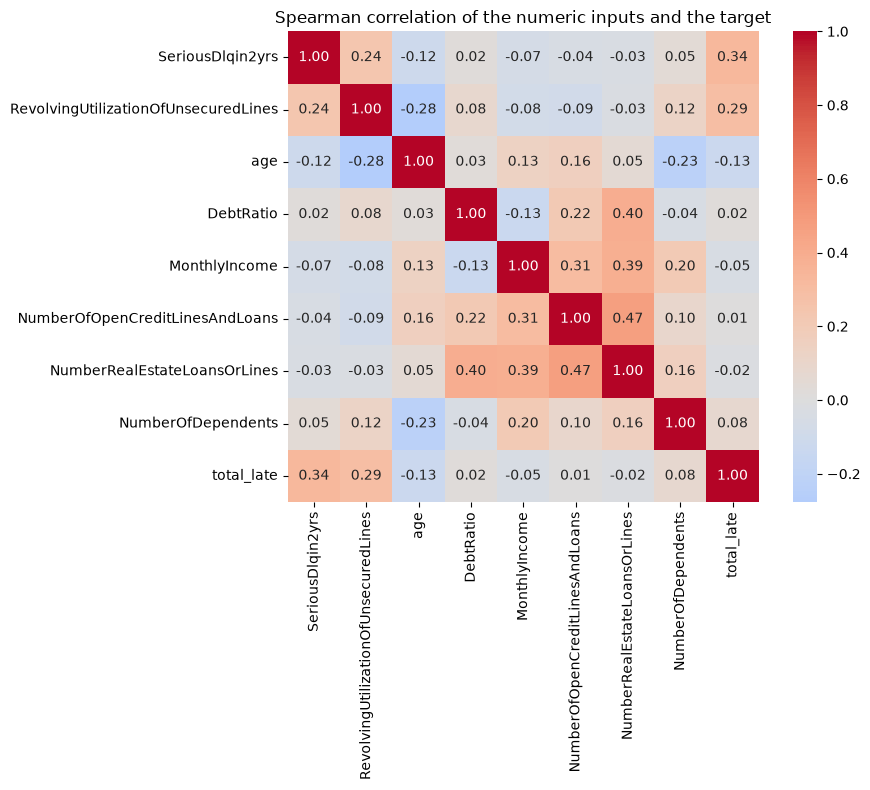

In [85]:
# Columns for the correlation matrix, including the target
corr_cols = ["SeriousDlqin2yrs", "RevolvingUtilizationOfUnsecuredLines", "age", "DebtRatio",
             "MonthlyIncome", "NumberOfOpenCreditLinesAndLoans", "NumberRealEstateLoansOrLines",
             "NumberOfDependents", "total_late"]

# Spearman correlation, which suits skewed data with extreme values
corr = fe[corr_cols].corr(method="spearman")

# Correlation of each input with the target, strongest first
print(corr["SeriousDlqin2yrs"].drop("SeriousDlqin2yrs").sort_values(key=abs, ascending=False).round(3))

# Heatmap of the full matrix
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, ax=ax)
ax.set_title("Spearman correlation of the numeric inputs and the target")
plt.tight_layout()
plt.show()

### What the debt ratio check shows

Among the 120,169 borrowers with a reported income, the median debt ratio is 0.30 and the 75th percentile is 0.48. Among the 29,221 borrowers with no reported income, the median is 1,198, the 25th percentile is 155 and the maximum is 329,664. About three in four of these borrowers have a debt ratio above 155, which cannot be a ratio, so the value is probably a raw amount. Decision: set DebtRatio to missing for borrowers without a reported income, add the column income_missing_flag, and fill the missing debt ratios after the train and test split with a value from the training part only. The raw amounts are lost for 29,221 rows, and the flag keeps the fact that income was not reported.

In [86]:
# Borrowers whose monthly income is missing
no_income = fe["MonthlyIncome"].isna()

# Flag that records that income was not reported
fe["income_missing_flag"] = no_income.astype(int)

# Set the debt ratio to missing where income is missing, because it is not a credible ratio there
fe.loc[no_income, "DebtRatio"] = np.nan

# Check the result
print("Rows with income missing:", no_income.sum())
print("Debt ratio missing now:", fe["DebtRatio"].isna().sum())
print(fe["DebtRatio"].describe(percentiles=[0.5, 0.9, 0.99]).round(2))

Rows with income missing: 29221
Debt ratio missing now: 29221
count    120169.00
mean         26.62
std         424.62
min           0.00
50%           0.30
90%           0.76
99%         662.98
max       61106.50
Name: DebtRatio, dtype: float64


# Module 5: Statistical analysis

## Confidence interval and group comparisons

A 95% confidence interval for the delinquency rate, then a Mann-Whitney U test for each numeric input to compare borrowers who became delinquent with those who did not. This test is used because the inputs are heavily skewed. With about 149,000 borrowers almost every p-value will be tiny, so the effect size matters more. The column prob_yes_higher is the chance that a randomly chosen delinquent borrower has a higher value than a randomly chosen non-delinquent borrower. A value of 0.5 means no difference.

In [87]:
# Import scipy for the tests
from scipy import stats

# Number of borrowers and the share who became delinquent
n = len(fe)
p = fe["SeriousDlqin2yrs"].mean()

# 95% confidence interval for the delinquency rate, using the normal approximation
se = np.sqrt(p * (1 - p) / n)
low, high = p - 1.96 * se, p + 1.96 * se
print(f"Delinquency rate: {p*100:.2f}% | 95% CI: {low*100:.2f}% to {high*100:.2f}%")

# Numeric inputs to compare between the two groups
test_cols = ["RevolvingUtilizationOfUnsecuredLines", "age", "DebtRatio", "MonthlyIncome",
             "NumberOfOpenCreditLinesAndLoans", "NumberRealEstateLoansOrLines",
             "NumberOfDependents", "total_late"]

# One row of results per input
rows = []
for col in test_cols:
    # Values for each group, dropping missing values
    yes = fe.loc[fe["SeriousDlqin2yrs"] == 1, col].dropna()
    no = fe.loc[fe["SeriousDlqin2yrs"] == 0, col].dropna()
    # Mann-Whitney U test, which suits skewed data
    u, pval = stats.mannwhitneyu(yes, no, alternative="two-sided")
    # Chance that a random delinquent borrower has a higher value than a random non-delinquent one
    prob = u / (len(yes) * len(no))
    rows.append({"input": col, "median_no": no.median(), "median_yes": yes.median(),
                 "prob_yes_higher": round(prob, 3), "p_value": f"{pval:.2e}"})

# Show the results table
print(pd.DataFrame(rows).to_string(index=False))

Delinquency rate: 6.70% | 95% CI: 6.57% to 6.83%
                               input   median_no  median_yes  prob_yes_higher   p_value
RevolvingUtilizationOfUnsecuredLines    0.133383    0.837702            0.778  0.00e+00
                                 age   52.000000   45.000000            0.365  0.00e+00
                           DebtRatio    0.292779    0.358997            0.561  3.96e-78
                       MonthlyIncome 5475.000000 4500.000000            0.424 1.75e-120
     NumberOfOpenCreditLinesAndLoans    8.000000    7.000000            0.454  9.99e-53
        NumberRealEstateLoansOrLines    1.000000    1.000000            0.462  1.85e-41
                  NumberOfDependents    0.000000    0.000000            0.546  5.14e-68
                          total_late    0.000000    1.000000            0.773  0.00e+00


### What the tests show

The delinquency rate is 6.70%, with a 95% confidence interval of 6.57% to 6.83%. The interval is narrow because there are 149,390 borrowers.

Every Mann-Whitney p-value is below 1e-40, and three print as 0, which means smaller than the computer can show. With this many borrowers every difference is statistically significant, so the effect size matters more. Utilisation (0.778) and total late payments (0.773) are the clear ones: a randomly chosen delinquent borrower has higher utilisation than a randomly chosen non-delinquent one 78% of the time. The median utilisation is 0.13 for borrowers who did not become delinquent and 0.84 for those who did, and the median for total late payments is 0 against 1.

Age (0.365) and income (0.424) lean the other way. Delinquent borrowers are younger (median 45 against 52) and earn less (median 4,500 against 5,475). Debt ratio (0.561), dependents (0.546), open credit lines (0.454) and real estate loans (0.462) are close to 0.5, so they separate the two groups only weakly. Real estate loans and dependents have a median of 1 and 0 in both groups, because most borrowers hold few of either.

## Chi-square tests and Bayes' theorem

A chi-square test checks whether delinquency depends on each grouped column. Cramer's V is the effect size, where 0 means no link and 1 means a perfect link. Bayes' theorem then turns the group rates into a statement about risk: the chance of delinquency given an event, such as being flagged, compared with the overall chance.

In [88]:
# Grouped columns to test against the target
group_cols = ["age_group", "income_band", "utilisation_band", "late_group"]

# One row of results per grouped column
results = []
for col in group_cols:
    # Table of group against delinquency counts
    table = pd.crosstab(fe[col], fe["SeriousDlqin2yrs"])
    # Chi-square test of independence
    chi2, pval, dof, expected = stats.chi2_contingency(table)
    # Cramer's V as the effect size
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    results.append({"column": col, "chi2": round(chi2, 1), "dof": dof, "cramers_v": round(v, 3), "p_value": f"{pval:.2e}"})
print(pd.DataFrame(results).to_string(index=False))

# Target and overall delinquency probability
y = fe["SeriousDlqin2yrs"]
p_d = y.mean()

# Function that applies Bayes' theorem for one event
def bayes(mask, name):
    # Chance of the event among delinquent borrowers
    p_e_given_d = mask[y == 1].mean()
    # Chance of the event among all borrowers
    p_e = mask.mean()
    # Posterior chance of delinquency given the event
    posterior = p_e_given_d * p_d / p_e
    # Same chance counted directly, as a check
    direct = y[mask].mean()
    print(f"{name}: prior {p_d*100:.2f}% | P(event|delinquent) {p_e_given_d*100:.2f}% | "
          f"P(event) {p_e*100:.2f}% | posterior {posterior*100:.2f}% | direct {direct*100:.2f}%")

# Three events to compare
bayes(fe["past_due_code_flag"] == 1, "Flagged code rows")
bayes(fe["utilisation_band"] == "Above 1", "Utilisation above 1")
bayes(fe["late_group"] == "3 or more", "3 or more late payments")

          column    chi2  dof  cramers_v   p_value
       age_group  1857.3    3      0.112  0.00e+00
     income_band   725.4    5      0.070 1.61e-154
utilisation_band 12623.4    3      0.291  0.00e+00
      late_group 22582.4    3      0.389  0.00e+00
Flagged code rows: prior 6.70% | P(event|delinquent) 1.36% | P(event) 0.15% | posterior 60.44% | direct 60.44%
Utilisation above 1: prior 6.70% | P(event|delinquent) 12.36% | P(event) 2.22% | posterior 37.25% | direct 37.25%
3 or more late payments: prior 6.70% | P(event|delinquent) 30.75% | P(event) 4.62% | posterior 44.55% | direct 44.55%


### What the chi-square tests and Bayes' theorem show

All four grouped columns are linked to delinquency, with every p-value below 1e-150. Cramer's V shows how strong each link is. Late payments are the strongest (0.389), followed by utilisation (0.291), age (0.112) and income (0.070). Income is the weakest partly because its groups do not follow a straight pattern: borrowers with an income of 0 or with missing income have lower rates than the 1 to 3,400 band.

Bayes' theorem turns the group rates into risk. The overall rate is 6.70%. A flagged code row is delinquent 60.44% of the time, about 9 times the overall rate. A borrower with utilisation above 1 is delinquent 37.25% of the time (about 5.6 times the overall rate) and a borrower with 3 or more late payments 44.55% of the time (about 6.6 times). The posterior from Bayes' theorem matches the direct count in all three cases, which checks the calculation.

A high posterior does not mean the rule finds many delinquent borrowers. Only 1.36% of delinquent borrowers are flagged code rows, 12.36% have utilisation above 1, and 30.75% have 3 or more late payments. No single rule comes close to the recall target of 60%, so the model has to combine several inputs. These are associations, not causes.

## Central Limit Theorem

Monthly income is heavily skewed. The theorem says the means of repeated samples still form a roughly normal shape as the sample size grows, with a spread of about the standard deviation divided by the square root of the sample size. Here 1,000 samples are drawn for sample sizes of 30 and 200, and the shape and spread of the sample means are compared with the original income values.

Income: skewness 114.01
n=30: skewness 14.37 | std of means 3514.5 | predicted std 2627.2
n=200: skewness 7.99 | std of means 1390.2 | predicted std 1017.5
n=2000: skewness 2.44 | std of means 343.9 | predicted std 321.8


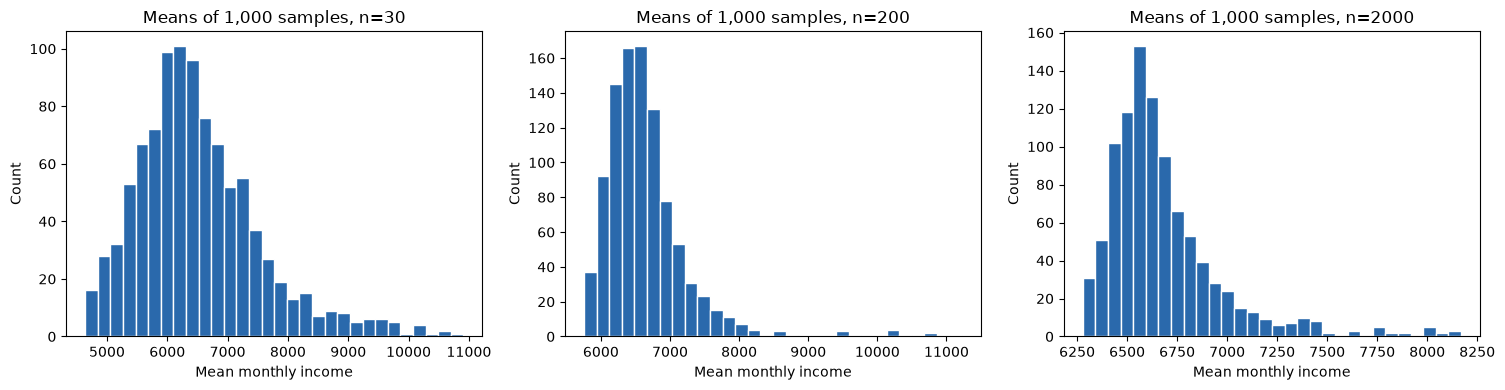

In [89]:
# Sample sizes to compare, now including a larger one
sizes = [30, 200, 2000]

# Fixed seed so every team member gets the same samples
rng = np.random.default_rng(42)

# Mean of each of 1,000 samples, for each sample size
means = {k: np.array([rng.choice(income.values, size=k, replace=False).mean() for _ in range(1000)]) for k in sizes}

# Skewness of the original income values
print("Income: skewness", round(stats.skew(income), 2))

# Skewness, spread and the spread the theorem predicts, for each sample size
for k in sizes:
    predicted = income.std() / np.sqrt(k)
    print(f"n={k}: skewness {stats.skew(means[k]):.2f} | std of means {means[k].std():.1f} | predicted std {predicted:.1f}")

# Three histograms, each zoomed to the middle 98% of its own sample means
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, k in zip(axes, sizes):
    # Limits at the 1st and 99th percentile of the sample means, for display only
    lo, hi = np.percentile(means[k], [1, 99])
    ax.hist(means[k][(means[k] >= lo) & (means[k] <= hi)], bins=30, color="#2a69ac", edgecolor="white")
    ax.set_title(f"Means of 1,000 samples, n={k}")
    ax.set_xlabel("Mean monthly income")
    ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

## Sprint 1 summary

The data is 150,000 borrowers from the Give Me Some Credit competition file. After cleaning stage A, 149,390 remain. The delinquency rate is 6.70% (95% confidence interval 6.57% to 6.83%).

### Cleaning log

| Issue | Rows | Decision |
|---|---|---|
| Duplicate rows | 609 | Removed |
| Age below 18 (an age of 0) | 1 | Removed |
| Codes 96 and 98 in the three past-due columns | 269 before duplicates were removed, 225 after | Set to missing and marked with past_due_code_flag. 60.44% of these borrowers became delinquent |
| Debt ratio where income is missing | 29,221 | Set to missing and marked with income_missing_flag, because it is not a credible ratio there |
| Monthly income missing | 29,221 after cleaning | To be filled in stage B, using the training part only |
| Dependents missing | 3,828 after cleaning | To be filled in stage B, using the training part only |
| Extreme values in utilisation, debt ratio and income | Not yet decided | Stage B, using the training part only |

### Main findings

1. Late payments and utilisation separate the borrowers most clearly. The delinquency rate is 2.7% with no late payments and 44.6% with 3 or more. It is 1.9% for utilisation up to 0.15 and 37.2% above 1. Cramer's V is 0.389 and 0.291.
2. Age and income matter less. Delinquent borrowers are younger (median 45 against 52) and earn less (median 4,500 against 5,475).
3. No single rule is enough. Flagged code rows, utilisation above 1 and 3 or more late payments catch only 1.36%, 12.36% and 30.75% of delinquent borrowers, so the model has to combine several inputs.
4. Income is far from normal (skewness 114.01). The skewness of sample means falls from 14.37 at n=30 to 2.44 at n=2000, so tests that assume a normal shape are avoided and medians and rank-based tests are used.

### Limits

These are associations, not causes. The sources checked do not state the country or the year of the data.

### Next

Train and test split, cleaning stage B from the training part only, a baseline model, then a stronger model.

In [90]:
# Confirm that fe exists and has the expected shape
print(fe.shape)

(149390, 20)
